# First-order RC low-pass filter - impulse (pulse) response and FFT

**Data source:** pulse captures taken by another group (`kenura/keysight-capture/data/sessions/1-pole_bode_data-{1,2,3}.json`), used with permission. They are read from `../kenura/` and are **not** copied into this repo (that folder is git-ignored).

Setup in the files: generator pulse 4 Vpp, 2 us wide, repeated at 100 Hz; CH1 = filter input, CH2 = filter output; 7679 samples at 65 ns (0.5 ms window).
The 2 us pulse is short compared with the filter time constant (~10 us), so it approximates a Dirac impulse and H(f) = FFT(Vout)/FFT(Vin).

The 2nd-order Chebyshev analysis is in `report.ipynb` (sine sweep) and is independent of this notebook.

In [1]:
import json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import least_squares
plt.rcParams.update({'figure.dpi':110,'axes.grid':True,'grid.alpha':.3})
SRC=Path('../kenura/keysight-capture/data/sessions')
FIG=Path('figures'); DATA=Path('data')
RUNS=[1,2,3]; FMAX=300e3

def load(k):
    d=json.load(open(SRC/f'1-pole_bode_data-{k}.json'))
    t=np.array(d['time_s']); vin=np.array(d['ch1_v']); vout=np.array(d['ch2_v'])
    n=len(t); dt=np.median(np.diff(t))
    # baseline from the last 10% of the record, where the pulse has died away
    vin=vin-np.median(vin[-n//10:]); vout=vout-np.median(vout[-n//10:])
    return t,vin,vout,dt

def bode(t,vin,vout,dt):
    X=np.fft.rfft(vin); Y=np.fft.rfft(vout); f=np.fft.rfftfreq(len(t),dt)
    ok=(f>0)&(f<FMAX)&(np.abs(X)>0.05*np.abs(X[1:]).max())
    return f,X,Y,ok

def model_db(f,g,fc): return 20*np.log10(g/np.sqrt(1+(f/fc)**2))
def model_ph(f,fc): return -np.degrees(np.arctan(f/fc))


## 1. Time domain: input pulse and filter response

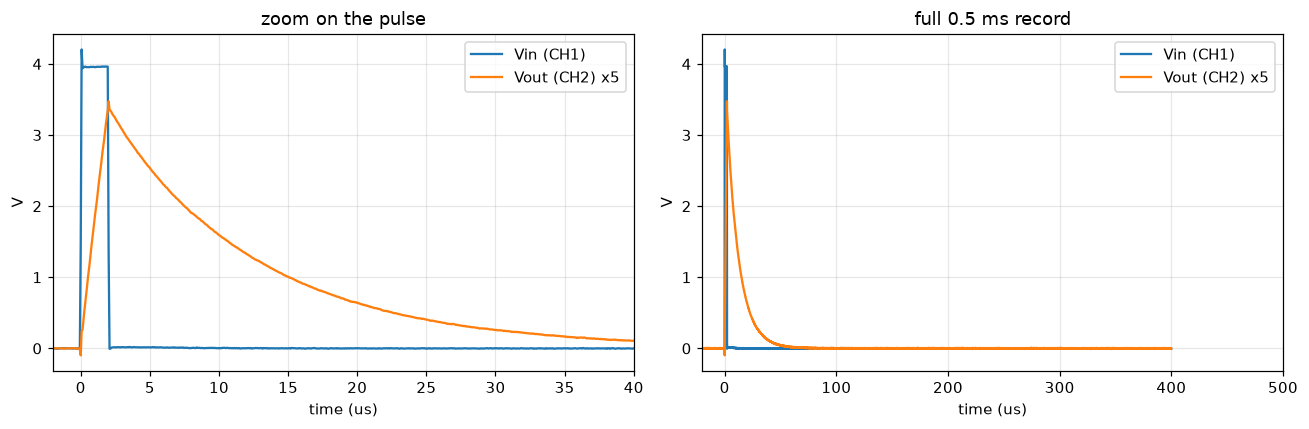

pulse width (FWHM): 1.95 us, sample interval 65.1 ns, record 0.50 ms -> df = 2000 Hz


In [2]:
data={k:load(k) for k in RUNS}
t,vin,vout,dt=data[3]
fig,ax=plt.subplots(1,2,figsize=(12,4))
for a,xl in zip(ax,[(-2,40),(-20,500)]):
    a.plot(t*1e6,vin,label='Vin (CH1)'); a.plot(t*1e6,vout*5,label='Vout (CH2) x5')
    a.set_xlim(*xl); a.set_xlabel('time (us)'); a.set_ylabel('V'); a.legend()
ax[0].set_title('zoom on the pulse'); ax[1].set_title('full 0.5 ms record')
plt.tight_layout(); plt.savefig(FIG/'lp_time_domain.png',dpi=200); plt.show()
print(f'pulse width (FWHM): {(vin>vin.max()/2).sum()*dt*1e6:.2f} us, sample interval {dt*1e9:.1f} ns, record {len(t)*dt*1e3:.2f} ms -> df = {1/(len(t)*dt):.0f} Hz')

## 2. Input spectrum - is the pulse a good impulse?
A 2 us rectangular pulse has a sinc spectrum: flat to ~100 kHz, first null at 1/(2 us) = 500 kHz. Bins where |Vin| falls below 5 % of its peak are discarded (and everything above 300 kHz).

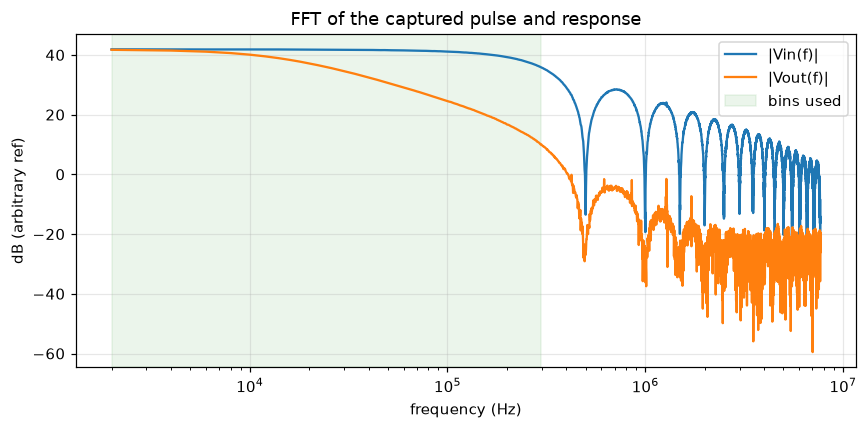

In [3]:
f,X,Y,ok=bode(*data[3][0:3],data[3][3])
fig,ax=plt.subplots(figsize=(8,4))
ax.semilogx(f[1:],20*np.log10(np.abs(X[1:])),label='|Vin(f)|')
ax.semilogx(f[1:],20*np.log10(np.abs(Y[1:])),label='|Vout(f)|')
ax.axvspan(f[ok].min(),f[ok].max(),color='g',alpha=.08,label='bins used')
ax.set_xlabel('frequency (Hz)'); ax.set_ylabel('dB (arbitrary ref)'); ax.legend(); ax.set_title('FFT of the captured pulse and response')
plt.tight_layout(); plt.savefig(FIG/'lp_fft_spectra.png',dpi=200); plt.show()

## 3. Bode plot from FFT, with first-order fit  H(f) = G / (1 + jf/fc)

In [4]:
rows=[];res={}
for k in RUNS:
    t,vin,vout,dt=data[k]; f,X,Y,ok=bode(t,vin,vout,dt)
    H=Y[ok]/X[ok]; fk=f[ok]
    r=least_squares(lambda p:20*np.log10(np.abs(H))-model_db(fk,*p),[1,10e3])
    g,fc=r.x; rms=np.sqrt(np.mean(r.fun**2))
    phase_rms=np.sqrt(np.mean((np.degrees(np.angle(H))-model_ph(fk,fc))**2))
    res[k]=dict(f=fk,H=H,g=g,fc=fc)
    rows.append(dict(run=k,bins=int(ok.sum()),passband_gain_dB=20*np.log10(g),fc_Hz=fc,mag_rms_err_dB=rms,phase_rms_err_deg=phase_rms,vin_adc_levels=len(np.unique(vin))))
fits=pd.DataFrame(rows); fits.to_csv(DATA/'lowpass_fit_summary.csv',index=False); fits.round(3)

,run,bins,passband_gain_dB,fc_Hz,mag_rms_err_dB,phase_rms_err_deg,vin_adc_levels
0,1,149,-0.134,15291.992,0.708,5.472,25
1,2,149,-0.269,15544.722,0.088,1.736,22
2,3,149,-0.291,15589.353,0.089,1.645,22


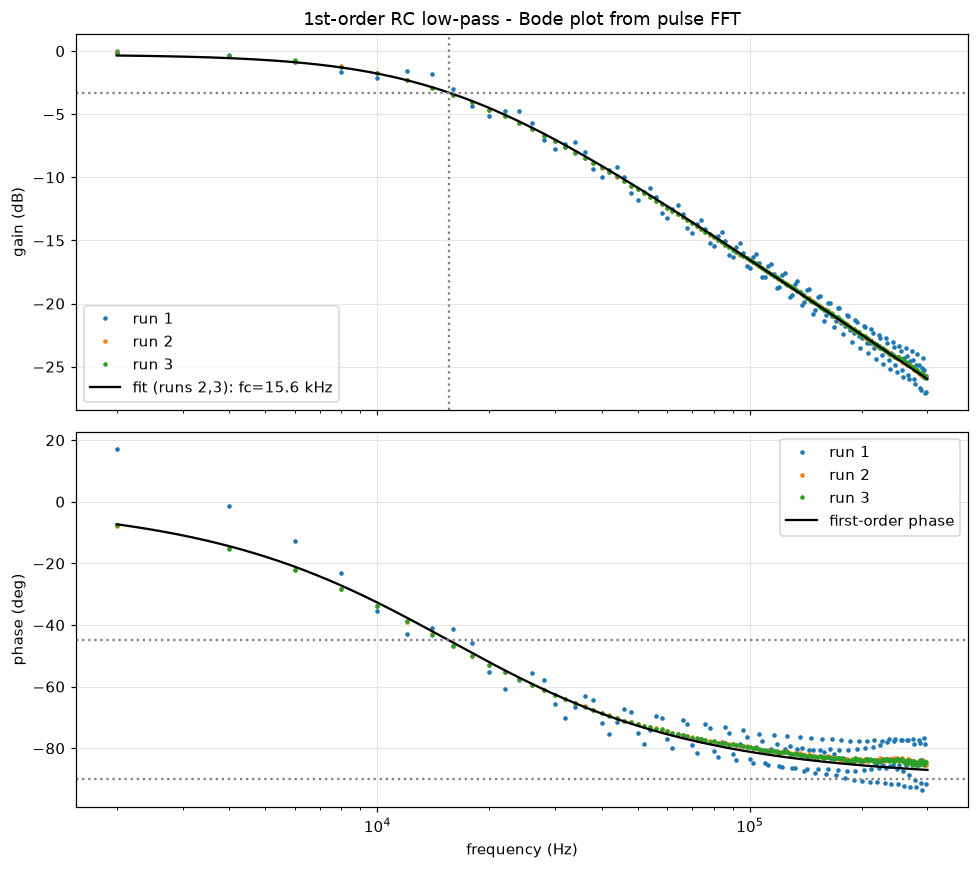

In [5]:
fig,(a1,a2)=plt.subplots(2,1,figsize=(9,8),sharex=True)
ff=np.logspace(3.3,np.log10(FMAX),400)
for k,col in zip(RUNS,['C0','C1','C2']):
    r=res[k]; a1.semilogx(r['f'],20*np.log10(np.abs(r['H'])),'.',ms=4,color=col,label=f'run {k}')
    a2.semilogx(r['f'],np.degrees(np.angle(r['H'])),'.',ms=4,color=col,label=f'run {k}')
good=[2,3]; g=np.mean([res[k]['g'] for k in good]); fc=np.mean([res[k]['fc'] for k in good])
a1.semilogx(ff,model_db(ff,g,fc),'k-',label=f'fit (runs 2,3): fc={fc/1e3:.1f} kHz')
a1.axhline(20*np.log10(g)-3.01,ls=':',color='gray'); a1.axvline(fc,ls=':',color='gray')
a2.semilogx(ff,model_ph(ff,fc),'k-',label='first-order phase'); a2.axhline(-45,ls=':',color='gray'); a2.axhline(-90,ls=':',color='gray')
a1.set_ylabel('gain (dB)'); a2.set_ylabel('phase (deg)'); a2.set_xlabel('frequency (Hz)')
a1.set_title('1st-order RC low-pass - Bode plot from pulse FFT'); a1.legend(); a2.legend()
plt.tight_layout(); plt.savefig(FIG/'lp_bode_fft.png',dpi=200); plt.show()

## 4. Cutoff frequency, roll-off and frequency identification
* **-3 dB cutoff** is read from the fit and also by linear interpolation of the measured points.
* **Roll-off** is the slope of the gain over a decade well above cutoff; a single pole gives -20 dB/decade.
* **Phase** should reach -45 deg at fc and tend to -90 deg.

In [6]:
out=[]
for k in RUNS:
    r=res[k]; fk=r['f']; gdb=20*np.log10(np.abs(r['H'])); ref=gdb[:3].mean()   # passband level from lowest bins
    i=np.where(gdb<ref-3.0103)[0][0]
    f3=np.interp(ref-3.0103,[gdb[i],gdb[i-1]],[fk[i],fk[i-1]])
    hi=(fk>=50e3)&(fk<=300e3)
    slope=np.polyfit(np.log10(fk[hi]),gdb[hi],1)[0]
    fc45=np.interp(-45,np.degrees(np.angle(r['H']))[::-1],fk[::-1])
    out.append(dict(run=k,fit_fc_Hz=r['fc'],interp_minus3dB_Hz=f3,phase_minus45_Hz=fc45,rolloff_dB_per_decade_50k_300k=slope,passband_dB=ref))
key=pd.DataFrame(out); key.to_csv(DATA/'lowpass_key_frequencies.csv',index=False)
key.round(2)

,run,fit_fc_Hz,interp_minus3dB_Hz,phase_minus45_Hz,rolloff_dB_per_decade_50k_300k,passband_dB
0,1,15291.99,16581.87,17572.25,-19.36,-0.39
1,2,15544.72,15759.57,15087.43,-19.38,-0.41
2,3,15589.35,15816.94,15035.70,-19.37,-0.42


In [7]:
# compare with the pulse-train spectral lines of the generator itself
print('Pulse repetition rate 100 Hz -> spectral lines every 100 Hz, but the 0.5 ms record only resolves', round(1/(len(t)*dt)),'Hz.')
print('Time constant from fit: tau = 1/(2 pi fc) = %.2f us' % (1e6/(2*np.pi*fc)))
t3,v_in,v_out,dt3=data[3]
# check in the time domain: first-order response to a short pulse decays as exp(-t/tau)
i0=np.argmax(v_out); tt=(t3[i0:]-t3[i0]); sel=(v_out[i0:]>0.05*v_out[i0])
p=np.polyfit(tt[sel],np.log(v_out[i0:][sel]),1); print('Decay tau from time-domain tail: %.2f us'%(-1e6/p[0]))

Pulse repetition rate 100 Hz -> spectral lines every 100 Hz, but the 0.5 ms record only resolves 2000 Hz.
Time constant from fit: tau = 1/(2 pi fc) = 10.22 us
Decay tau from time-domain tail: 10.98 us


## 5. Notes / limitations (state these in the report)
* **Frequency resolution is 2 kHz** (0.5 ms record), so only ~7 bins lie below fc. The fit uses ~150 bins up to 300 kHz, so fc is well determined, but individual low-frequency points are coarse.
* **Run 1 is noisier** (CH1 used only ~20 ADC levels) - runs 2 and 3 are the cleaner pair.
* The R and C values of this group's filter are not in the files. Fit result is a measurement of fc, not compared with a design value. (Our own RC design was R = 2400 ohm, C = 10 nF, fc = 6.63 kHz - the fitted fc here is about 15.5 kHz, so this is a different component set.)